# ECON 422 · Macroeconomics and Machine Learning
## Deep Learning with Real Economic Data — Three Hands-On Exercises

**Four cells to run:** First run **Cell 0 — Source URLs** once. Then run **any one** of the three exercises by clicking ▶ once. You do not need to run the other exercises.

| Exercise | Real-world input | Deep-learning task | Output |
|:--|:--|:--|:--|
| **1. LLM** | Federal Reserve FOMC statements | Assess monetary-policy **tone** | Hawkish, dovish, or neutral, with a reason |
| **2. ASR + LLM** | A recorded Federal Reserve speech | **Whisper transcribes** and **an LLM summarizes** | Audio excerpt, transcript, summary |
| **3. CNN + macroeconomics** | NASA nighttime-light maps and FRED unemployment | Classify image patches and compare to a regional economic indicator | Images, illustrative light index, unemployment plot |

**Source management:** Every public data URL is defined only in the first code cell using `BASE_URLS` and `DATA_URLS`. You can **copy and paste** that entire cell into another notebook. All three exercise cells read the URLs from `DATA_URLS` — they contain no duplicate hard-coded source links.

**Run order:** (1) **Run the URL cell** → (2) **click ▶ on the exercise of your choice**. Run the URL cell again if you edit a URL. Missing Python packages are installed automatically by each exercise, and real-data/model downloads require internet access. No paid API key is needed.

**Interpretation:** The LLM may misclassify tone or produce an imperfect summary. The CNN distinguishes *before vs. after* satellite image patches; the light-display index is not GDP, radiance, or verified outages. Comparing it with unemployment is descriptive, not causal evidence.


---
## Cell 0 — Source URLs (run this **once** first)

This is the single place to copy, paste, or edit the data sources. `BASE_URLS` lists the website roots, while `DATA_URLS` builds the **exact pages and downloadable files** used in the exercises. Running the box prints all the complete links for easy copying.

You do **not** need to edit any exercise cell. For example, the CNN reads `DATA_URLS["nasa_before"]`, `DATA_URLS["nasa_after"]`, and `DATA_URLS["lee_unemployment_csv"]` from this box.


In [1]:
# Copy and paste the URLs from Quizzes '[Week8] Exercise'.
BASE_URLS = {
"federal_reserve": "https://www.federalreserve.gov/newsevents/pressreleases/",
"fraser": "https://fraser.stlouisfed.org/",
"nasa_images": "https://svs.gsfc.nasa.gov/vis/a000000/a005000/a005058/",
"nasa_website": "https://svs.gsfc.nasa.gov/",
"fred": "https://fred.stlouisfed.org/",
}

DATA_URLS = {
# Exercise 1: Federal Reserve policy statements
"fomc_march_2022": BASE_URLS["federal_reserve"] + "monetary20220316a.htm",
"fomc_september_2024": BASE_URLS["federal_reserve"] + "monetary20240918a.htm",

# Exercise 2: Federal Reserve speech recording (MP3) and its archive page
"fed_speech_audio": BASE_URLS["fraser"] + "files/docs/historical/frbatl/speeches/frbatl_lockhart_20100603.mp3",
"fed_speech_page": BASE_URLS["fraser"] + "title/5579/item/558004/content/mp3/frbatl_lockhart_20100603",

# Exercise 3: NASA nightlights before/after Hurricane Ian and unemployment data
"nasa_before": BASE_URLS["nasa_images"] + "black_marble_aug2160_print.jpg",
"nasa_after": BASE_URLS["nasa_images"] + "black_marble_sep2160_print.jpg",
"nasa_page": BASE_URLS["nasa_website"] + "5058",
"lee_unemployment_csv": BASE_URLS["fred"] + "graph/fredgraph.csv?id=FLLEEC7URN",
"lee_unemployment_page": BASE_URLS["fred"] + "series/FLLEEC7URN",
}

print("Source URLs are ready. Copy any complete link below if needed:\n")
for name, url in DATA_URLS.items():
    print(f"{name:<25} {url}")
print("\nNow click ▶ on Exercise 1, 2, or 3.")

Source URLs are ready. Copy any complete link below if needed:

fomc_march_2022           https://www.federalreserve.gov/newsevents/pressreleases/monetary20220316a.htm
fomc_september_2024       https://www.federalreserve.gov/newsevents/pressreleases/monetary20240918a.htm
fed_speech_audio          https://fraser.stlouisfed.org/files/docs/historical/frbatl/speeches/frbatl_lockhart_20100603.mp3
fed_speech_page           https://fraser.stlouisfed.org/title/5579/item/558004/content/mp3/frbatl_lockhart_20100603
nasa_before               https://svs.gsfc.nasa.gov/vis/a000000/a005000/a005058/black_marble_aug2160_print.jpg
nasa_after                https://svs.gsfc.nasa.gov/vis/a000000/a005000/a005058/black_marble_sep2160_print.jpg
nasa_page                 https://svs.gsfc.nasa.gov/5058
lee_unemployment_csv      https://fred.stlouisfed.org/graph/fredgraph.csv?id=FLLEEC7URN
lee_unemployment_page     https://fred.stlouisfed.org/series/FLLEEC7URN

Now click ▶ on Exercise 1, 2, or 3.


---
## Exercise 1 — LLM: Is Fed Communication Hawkish, Dovish, or Neutral?

**Economic question:** Does a real FOMC statement sound **hawkish** (leaning toward tighter monetary policy), **dovish** (leaning toward easier monetary policy), or **neutral**?

**How the code box works:**

1. Downloads two **real FOMC statements** (March 16, 2022; September 18, 2024).
2. Gives the statements to a **pretrained LLM**, together with simple definitions of the three tones.
3. The LLM **decides the tone for each statement** and gives a **one-sentence reason**, citing the policy language. Its answer is generated one token at a time.

**Action:** First run the **Source URLs** cell at the top, then click **▶ Run** below. Compare the model labels with the actual policy text.

**Data sources:** FOMC statements are retrieved from `DATA_URLS["fomc_march_2022"]` and `DATA_URLS["fomc_september_2024"]`.

**Think about:** Is the Fed's **tone** always the same as the **current level** of the interest rate? Could the model mistake cautious language for a neutral policy stance?

In [2]:
# EXERCISE 1: ONE CLICK — REAL FED TEXT -> LLM POLICY TONE
import sys, subprocess, importlib.util
required = {"requests": "requests", "bs4": "beautifulsoup4",
            "torch": "torch", "transformers": "transformers>=4.48,<5"}
missing = [package for module, package in required.items()
           if importlib.util.find_spec(module) is None]
if missing:
    print("Installing missing packages (first run only)...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

import requests, torch
from bs4 import BeautifulSoup
from transformers import AutoTokenizer, AutoModelForCausalLM

torch.set_num_threads(min(4, torch.get_num_threads()))

# These links are defined in the first code cell; no URLs are hard-coded here.
if "DATA_URLS" not in globals():
    raise RuntimeError("Run Cell 0 — Source URLs first, then retry Exercise 1.")

# REAL Federal Reserve statements; the embedded extracts are a backup only.
statements = {
    "March 16, 2022": DATA_URLS["fomc_march_2022"],
    "September 18, 2024": DATA_URLS["fomc_september_2024"],
}
fallbacks = {
    "March 16, 2022": (
        "Indicators of economic activity and employment have continued to strengthen. "
        "Inflation remains elevated, reflecting supply and demand imbalances related to "
        "the pandemic, higher energy prices, and broader price pressures. "
        "The Committee decided to raise the target range for the federal funds rate "
        "to 1/4 to 1/2 percent and anticipates that ongoing increases in the target "
        "range will be appropriate."
    ),
    "September 18, 2024": (
        "Job gains have slowed, and the unemployment rate has moved up but remains low. "
        "Inflation has made further progress toward the Committee's 2 percent objective "
        "but remains somewhat elevated. The Committee has gained greater confidence that "
        "inflation is moving sustainably toward 2 percent. In light of the progress on "
        "inflation and the balance of risks, the Committee decided to lower the target "
        "range for the federal funds rate by 1/2 percentage point to 4-3/4 to 5 percent."
    ),
}

def get_real_statement(date, url):
    try:
        response = requests.get(url, timeout=20,
                                headers={"User-Agent": "Mozilla/5.0"})
        response.raise_for_status()
        paragraphs = [p.get_text(" ", strip=True)
                      for p in BeautifulSoup(response.text, "html.parser").find_all("p")]
        # Find the monetary-policy decision, then include surrounding economic context.
        k = next(i for i, p in enumerate(paragraphs)
                 if "Committee decided" in p and "target range" in p)
        context = " ".join(paragraphs[max(0, k - 2):k + 1])
        if not ("inflation" in context.lower() and "federal funds" in context.lower()):
            raise ValueError("Could not reliably identify the policy text")
        return context[:1600], "official website"
    except Exception as exc:
        print(f"{date}: live page unavailable ({type(exc).__name__}); using an official excerpt.")
        return fallbacks[date], "embedded excerpt from official statement"

print("Loading a small, free pretrained LLM...")
try:
    model_id = "HuggingFaceTB/SmolLM2-135M-Instruct"
    tokenizer = AutoTokenizer.from_pretrained(model_id)
    llm = AutoModelForCausalLM.from_pretrained(model_id).eval()

    for date, url in statements.items():
        text, source = get_real_statement(date, url)
        print("\n" + "=" * 68)
        print(f"REAL FOMC STATEMENT: {date} ({source})")
        print("Source:", url)
        print("\nPolicy text:\n", text)

        prompt = (
            "Read this genuine Federal Reserve statement and decide its monetary-policy tone.\n"
            "Labels:\n"
            "HAWKISH = language favoring tighter policy or emphasizing inflation control.\n"
            "DOVISH = language favoring easier policy or emphasizing support for employment.\n"
            "NEUTRAL = no clear tilt in either direction.\n"
            "Focus on the *direction and wording of policy*, not just the interest-rate level.\n"
            "Use only this text. Reply with exactly two short lines:\n"
            "Tone: HAWKISH or DOVISH or NEUTRAL\n"
            "Reason: one sentence referring to language in the statement.\n\n"
            f"Statement ({date}):\n{text}"
        )
        messages = [
            {"role": "system", "content": "You are a concise macroeconomics teaching assistant."},
            {"role": "user", "content": prompt},
        ]
        encoded = tokenizer.apply_chat_template(
            messages, tokenize=True, add_generation_prompt=True,
            return_dict=True, return_tensors="pt")
        with torch.inference_mode():
            tokens = llm.generate(**encoded, max_new_tokens=95, do_sample=False,
                                  pad_token_id=tokenizer.eos_token_id)
        result = tokenizer.decode(
            tokens[0, encoded["input_ids"].shape[-1]:],
            skip_special_tokens=True).strip()
        print("\nLLM-DECIDED MONETARY-POLICY TONE:\n" + result)

    print("\nCHECK THE EVIDENCE: March 2022 announced a rate increase; September 2024 a rate cut.")
    print("The LLM's tone labels are illustrative and may be wrong; verify with the quoted text.")
except Exception as exc:
    print("\nCould not run the pretrained LLM; initial model downloads need internet.")
    print(f"{type(exc).__name__}: {str(exc)[:400]}")


c:\Users\mbadi\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading a small, free pretrained LLM...


c:\Users\mbadi\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\mbadi\.cache\huggingface\hub\models--HuggingFaceTB--SmolLM2-135M-Instruct. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Xet Storage is enabled for this repo, but the 'hf_xet' package is not installe


REAL FOMC STATEMENT: March 16, 2022 (official website)
Source: https://www.federalreserve.gov/newsevents/pressreleases/monetary20220316a.htm

Policy text:
 Indicators of economic activity and employment have continued to strengthen. Job gains have been strong in recent months, and the unemployment rate has declined substantially. Inflation remains elevated, reflecting supply and demand imbalances related to the pandemic, higher energy prices, and broader price pressures. The invasion of Ukraine by Russia is causing tremendous human and economic hardship. The implications for the U.S. economy are highly uncertain, but in the near term the invasion and related events are likely to create additional upward pressure on inflation and weigh on economic activity. The Committee seeks to achieve maximum employment and inflation at the rate of 2 percent over the longer run. With appropriate firming in the stance of monetary policy, the Committee expects inflation to return to its 2 percent obje

---
## Exercise 2 — ASR + LLM: Summarize a Real Federal Reserve Speech

**Economic question:** Can we **summarize the economic concerns expressed in a recorded central-bank speech**?

**How the code box works:**

1. Downloads **real audio** from Atlanta Fed President Dennis Lockhart's June 3, 2010 speech, *Sources of Employment Uncertainty* (FRASER archive).
2. Plays part of the recording; **Whisper ASR** converts three short excerpts from **speech into text**.
3. A small **LLM reads the transcript and writes a two-sentence summary** of what it actually says.

**Important:** **ASR produces the transcript; the LLM produces the summary.** We summarize about a minute of **selected excerpts**, **not the entire speech**. Errors in transcription may affect the summary.

**Action:** Run the **Source URLs** cell once, then click **▶ Run** here; nothing to type or upload.

**Official recording:** Defined as `DATA_URLS["fed_speech_audio"]` (archive page: `DATA_URLS["fed_speech_page"]`).

**Think about:** How might summaries of **many dated speeches** help researchers study changing concerns about inflation or unemployment?

Installing missing packages (first run only)...
REAL SOURCE: Dennis Lockhart, Atlanta Fed — June 3, 2010
https://fraser.stlouisfed.org/title/5579/item/558004/content/mp3/frbatl_lockhart_20100603

Playing a real 25-second audio excerpt:


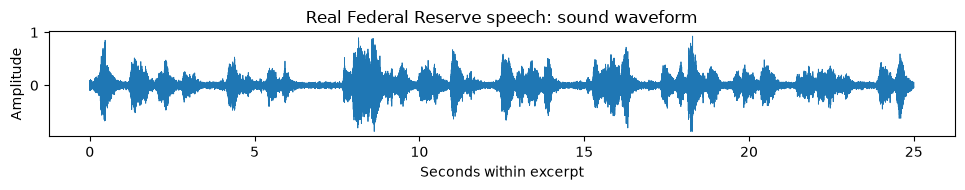


Step 1 — Whisper converts speech to written text...


c:\Users\mbadi\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\mbadi\.cache\huggingface\hub\models--openai--whisper-tiny.en. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling ba

  [ 35–60 s] Americans always flew in and still be in point of heart. I'm aware that a high exchange of community and technical college students are over the age of 30. In the case of the high-tech, almost 45% are over 30, and over 21% are over 40%.
  [ 75–100 s] in the economy, both at the macroeconomic level and at a personal level, that are so necessary and is dynamic and cool and economy. This morning, I want to focus on what might be viewed as a post-lane and person-drating aspect of the economic recovery that's underway.
  [115–140 s] about the lives of 2009. So the economy is emerging 12 months from staying recovery. And yet not much is happening in employment markets to reduce the high-level druglessness. Now how can that be? Over the last three quarters, gross domestic product has expanded and ours annualized grade

AUTOMATIC TRANSCRIPT (selected excerpts):
Americans always flew in and still be in point of heart. I'm aware that a high exchange of community and technical colleg

In [3]:
# EXERCISE 2: ONE CLICK — REAL FED AUDIO -> WHISPER TRANSCRIPT -> LLM SUMMARY
import sys, subprocess, importlib.util
required = {"requests": "requests", "numpy": "numpy", "matplotlib": "matplotlib",
            "imageio_ffmpeg": "imageio-ffmpeg", "torch": "torch",
            "transformers": "transformers>=4.48,<5"}
missing = [package for module, package in required.items()
           if importlib.util.find_spec(module) is None]
if missing:
    print("Installing missing packages (first run only)...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

import requests, numpy as np, matplotlib.pyplot as plt, torch
import imageio_ffmpeg
from IPython.display import Audio, display
from transformers import (WhisperProcessor, WhisperForConditionalGeneration,
                          AutoTokenizer, AutoModelForCausalLM)

torch.set_num_threads(min(4, torch.get_num_threads()))

# Read the source links defined in the first code cell.
if "DATA_URLS" not in globals():
    raise RuntimeError("Run Cell 0 — Source URLs first, then retry Exercise 2.")
audio_url = DATA_URLS["fed_speech_audio"]
source_page = DATA_URLS["fed_speech_page"]
print("REAL SOURCE: Dennis Lockhart, Atlanta Fed — June 3, 2010")
print(source_page)

try:
    # Download a bounded prefix of the recording (sufficient for our excerpt times).
    with requests.get(audio_url, stream=True, timeout=45,
                      headers={"User-Agent": "Mozilla/5.0", "Range": "bytes=0-3499999"}) as r:
        r.raise_for_status()
        pieces, n_bytes = [], 0
        for piece in r.iter_content(chunk_size=65536):
            if piece:
                pieces.append(piece)
                n_bytes += len(piece)
                if n_bytes >= 3_500_000:
                    break
    mp3_data = b"".join(pieces)
    if len(mp3_data) < 50_000:
        raise RuntimeError("The recording download returned too little audio")

    # ffmpeg converts compressed MP3 to 16-kHz mono waveform (Whisper's input).
    def decode_excerpt(start_seconds, duration_seconds=25):
        command = [imageio_ffmpeg.get_ffmpeg_exe(), "-hide_banner", "-loglevel", "error",
                   "-f", "mp3", "-i", "pipe:0", "-ss", str(start_seconds),
                   "-t", str(duration_seconds), "-ar", "16000", "-ac", "1",
                   "-f", "f32le", "pipe:1"]
        decoded = subprocess.run(command, input=mp3_data, stdout=subprocess.PIPE,
                                 stderr=subprocess.PIPE, check=False)
        return np.frombuffer(decoded.stdout, dtype="<f4").copy()

    # Three excerpts (about 75 seconds total) make a more informative summary.
    clips = []
    for start in [35, 75, 115]:
        clip = decode_excerpt(start, 25)
        if len(clip) >= 8 * 16000:
            clips.append((start, clip))
    if not clips:
        first_clip = decode_excerpt(0, 25)
        if len(first_clip) >= 8 * 16000:
            clips = [(0, first_clip)]
    if not clips:
        raise RuntimeError("Could not decode a usable audio excerpt")

    print(f"\nPlaying a real {len(clips[0][1])/16000:.0f}-second audio excerpt:")
    display(Audio(clips[0][1], rate=16000))
    plt.figure(figsize=(10, 2))
    plt.plot(np.arange(len(clips[0][1])) / 16000, clips[0][1], linewidth=0.6)
    plt.title("Real Federal Reserve speech: sound waveform")
    plt.xlabel("Seconds within excerpt")
    plt.ylabel("Amplitude")
    plt.tight_layout()
    plt.show()

    print("\nStep 1 — Whisper converts speech to written text...")
    processor = WhisperProcessor.from_pretrained("openai/whisper-tiny.en")
    whisper = WhisperForConditionalGeneration.from_pretrained("openai/whisper-tiny.en").eval()
    transcript_parts = []
    for start, clip in clips:
        features = processor(clip, sampling_rate=16000,
                             return_tensors="pt").input_features
        with torch.inference_mode():
            token_ids = whisper.generate(features, max_new_tokens=160)
        part = processor.batch_decode(token_ids, skip_special_tokens=True)[0].strip()
        transcript_parts.append(part)
        print(f"  [{start:>3}–{start + len(clip)/16000:.0f} s] {part}")

    transcript = " ".join(transcript_parts).strip()
    if not transcript:
        raise RuntimeError("Whisper returned an empty transcript")
    print("\nAUTOMATIC TRANSCRIPT (selected excerpts):\n" + transcript)

    print("\nStep 2 — A pretrained LLM summarizes the ASR transcript...")
    # Delete the ASR model before loading the language model to reduce memory use.
    del whisper
    model_id = "HuggingFaceTB/SmolLM2-135M-Instruct"
    tokenizer = AutoTokenizer.from_pretrained(model_id)
    llm = AutoModelForCausalLM.from_pretrained(model_id).eval()
    prompt = (
        "Summarize the following automatic transcript of excerpts from a real "
        "Federal Reserve speech in TWO short sentences, using only the transcript. "
        "Focus on the economic issues actually mentioned. "
        "Do NOT invent missing facts or describe the full speech. "
        "If these excerpts contain no substantive economic argument, state that.\n\n"
        "TRANSCRIPT:\n" + transcript[:4500]
    )
    messages = [
        {"role": "system", "content": "You write concise, source-grounded summaries."},
        {"role": "user", "content": prompt},
    ]
    encoded = tokenizer.apply_chat_template(
        messages, tokenize=True, add_generation_prompt=True,
        return_dict=True, return_tensors="pt")
    with torch.inference_mode():
        output_ids = llm.generate(**encoded, max_new_tokens=105, do_sample=False,
                                  pad_token_id=tokenizer.eos_token_id)
    summary = tokenizer.decode(
        output_ids[0, encoded["input_ids"].shape[-1]:],
        skip_special_tokens=True).strip()
    print("\nLLM SUMMARY OF THE TRANSCRIBED EXCERPTS:\n" + summary)
    print("\nCheck that every claim in the summary appears in the transcript.")
    print("These are sampled excerpts, not a full-speech summary.")
except Exception as exc:
    print("\nThe recording, ASR, or LLM could not be loaded; initial downloads need internet.")
    print(f"{type(exc).__name__}: {str(exc)[:450]}")


---
## Exercise 3 — CNN: Nighttime Lights and Employment

**Economic question:** Can satellite images reveal a regional disruption, and how does that disruption compare with **observed local labor-market conditions**?

**How the code box works:**

1. Download two **real NASA nighttime-light maps** of southwest Florida: August 30, 2022 (**before Hurricane Ian**) and September 30, 2022 (**after**).
2. Train a small **CNN** to distinguish the before/after image patches. Display its classification accuracy for held-out map locations.
3. Calculate an **illustrative nighttime-light display index**, normalized to **100 before the hurricane**. This is based on colors in NASA's rendered visualization—not calibrated satellite radiance or GDP.
4. Load **real monthly unemployment** for **Lee County, Florida** from FRED, and plot the observed changes around the hurricane. The code includes a few source-verified FRED observations as a backup if the live CSV cannot be fetched.

**Macro interpretation:** Economic activity and electricity use can influence nighttime lights. After a hurricane, darker imagery may reflect outages or infrastructure disruption, while unemployment may capture a related—but not identical—labor-market response. Comparing both is **descriptive**, not evidence that lights caused unemployment or an estimate of GDP.

**Action:** Run **Cell 0 — Source URLs** once, then click **▶ Run** on the next cell. No URLs need to be typed inside the exercise.

**Real data:** NASA imagery is specified by `DATA_URLS["nasa_before"]` and `DATA_URLS["nasa_after"]`; FRED unemployment is specified by `DATA_URLS["lee_unemployment_csv"]`. NASA visualization by Michala Garrison (SSAI), based on NASA Black Marble / Suomi NPP VIIRS data.

**Think about:** Why might a September 30 nighttime-light disruption be more closely reflected in the **October** labor-market data than the September unemployment estimate? What further dates and regions would be required to predict economic recovery?


Downloaded real NASA image: Before | Aug 30, 2022 (1024 x 288)
Downloaded real NASA image: After | Sep 30, 2022 (1024 x 288)


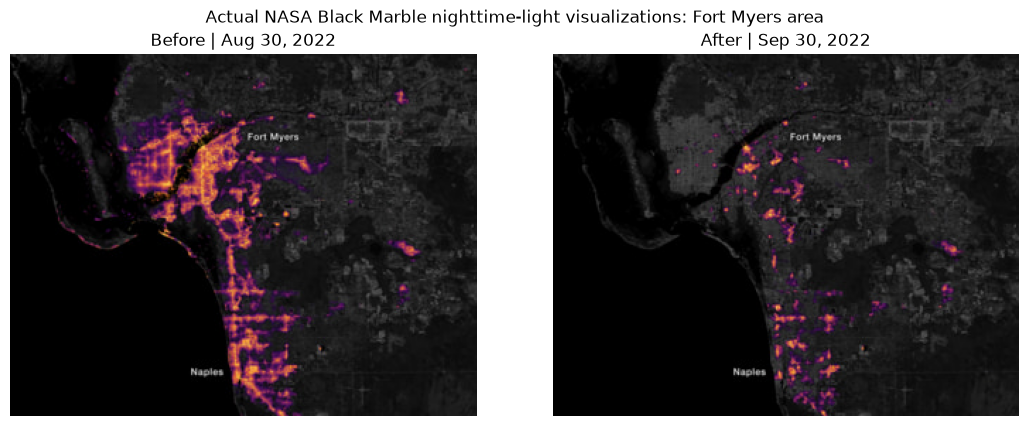


CNN classification accuracy (before vs. after; held-out patches): 63%
Illustrative nighttime-light DISPLAY index: 100.0 before → 27.8 after
This image-color index describes NASA's rendered visualization; it is NOT GDP or radiance.
FRED CSV unavailable; using historical FRED observations: ReadTimeout


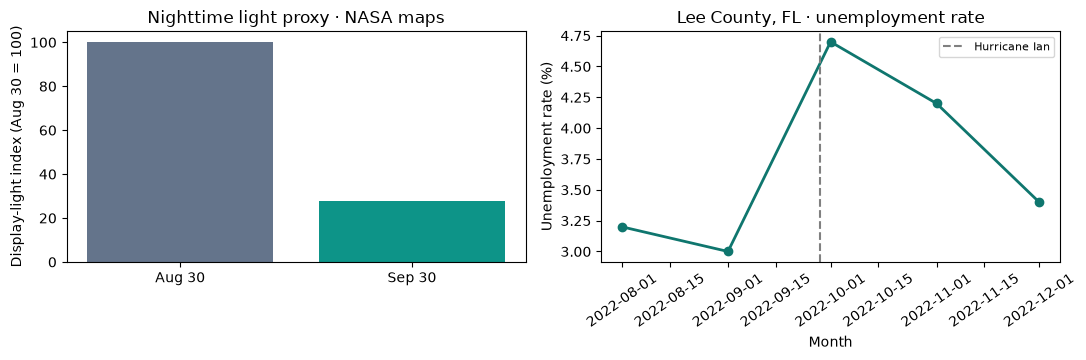


Real macro series: embedded FRED historical observations (Aug–Dec 2022)
Lee County unemployment: 3.2% (Aug 2022) → 4.7% (Oct 2022),
a change of +1.5 percentage points.
Research interpretation: temporary power disruptions can reduce local activity,
while observed unemployment is a separate economic outcome. These two snapshots
do not identify an effect of the hurricane, validate a light-to-GDP relationship,
or establish out-of-sample forecasting performance.
Sources: https://svs.gsfc.nasa.gov/5058  |  https://fred.stlouisfed.org/series/FLLEEC7URN


In [4]:
# EXERCISE 3: ONE CLICK — REAL NASA NIGHTTIME LIGHTS + CNN
import sys, subprocess, importlib.util
packages = {"requests":"requests", "PIL":"pillow", "numpy":"numpy",
            "matplotlib":"matplotlib", "torch":"torch"}
missing = [p for m,p in packages.items() if importlib.util.find_spec(m) is None]
if missing:
    print("Installing missing packages (first run only)...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

import io, requests, numpy as np, matplotlib.pyplot as plt, torch
from PIL import Image
from torch import nn
from torch.nn import functional as F

torch.manual_seed(422)
torch.set_num_threads(min(4, torch.get_num_threads()))
rng = np.random.default_rng(422)

# The NASA and FRED links come exclusively from Cell 0.
if "DATA_URLS" not in globals():
    raise RuntimeError("Run Cell 0 — Source URLs first, then retry Exercise 3.")
urls = {
    "Before | Aug 30, 2022": DATA_URLS["nasa_before"],
    "After | Sep 30, 2022": DATA_URLS["nasa_after"],
}
fred_url = DATA_URLS["lee_unemployment_csv"]

try:
    maps = []
    for label, url in urls.items():
        response = requests.get(url, timeout=35, headers={"User-Agent": "Mozilla/5.0"})
        response.raise_for_status()
        img = Image.open(io.BytesIO(response.content)).convert("RGB")
        maps.append(np.asarray(img, dtype=np.float32)/255.0)
        print(f"Downloaded real NASA image: {label} ({img.width} x {img.height})")
    before, after = maps
    if before.shape != after.shape:
        raise ValueError("Before/after maps have mismatched dimensions")

    # Omit the bottom date/caption strip. This is processed color imagery, NOT calibrated radiance.
    before, after = before[:256], after[:256]
    patch = 32
    locations = [(y,x) for y in range(0, before.shape[0]-patch+1, patch)
                       for x in range(0, before.shape[1]-patch+1, patch)]

    # Focus on actual locations with bright colored features in the pre-hurricane image.
    def color_light_signal(arr):
        return np.maximum(arr[...,0]-arr[...,1], 0) + 0.25*np.maximum(arr[...,2]-arr[...,1],0)
    scores = [float(color_light_signal(before[y:y+patch, x:x+patch]).mean()) for y,x in locations]
    best = np.argsort(scores)[-min(120, len(locations)):]
    locations = [locations[int(i)] for i in best]
    rng.shuffle(locations)
    split = int(.75*len(locations))
    train_locations, test_locations = locations[:split], locations[split:]

    # Real labeled patches: 0 = before; 1 = after (labels are IMAGE DATES, not outage status).
    def make_dataset(place_list):
        images = [before[y:y+patch,x:x+patch] for y,x in place_list] + \
                 [after[y:y+patch,x:x+patch] for y,x in place_list]
        labels = [0]*len(place_list) + [1]*len(place_list)
        X = torch.tensor(np.stack(images), dtype=torch.float32).permute(0,3,1,2)
        y = torch.tensor(labels, dtype=torch.long)
        return X, y
    X_train, y_train = make_dataset(train_locations)
    X_test, y_test = make_dataset(test_locations)

    # Small CNN learns filters directly from these real image patches.
    cnn = nn.Sequential(
        nn.Conv2d(3, 12, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(12, 16, 3, padding=1), nn.ReLU(),
        nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(16, 2)
    )
    optimizer = torch.optim.Adam(cnn.parameters(), lr=.006)
    for epoch in range(30):
        cnn.train()
        for ids in torch.randperm(len(X_train)).split(32):
            loss = F.cross_entropy(cnn(X_train[ids]), y_train[ids])
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

    cnn.eval()
    with torch.inference_mode():
        probabilities = F.softmax(cnn(X_test), dim=1)[:,1].numpy()
    accuracy = float(np.mean((probabilities >= .5) == y_test.numpy()))

    # Show the actual NASA data (Fort Myers area, first large panel).
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
    for ax, data, label in zip(axes, [before, after], list(urls.keys())):
        ax.imshow(data[:, :330])
        ax.set_title(label)
        ax.axis("off")
    fig.suptitle("Actual NASA Black Marble nighttime-light visualizations: Fort Myers area")
    plt.tight_layout()
    plt.show()

    # ECONOMIC ACTIVITY PROXY: colors in the NASA visualization (not calibrated radiance).
    # The fixed picture crop is the first city panel, centered near Fort Myers.
    m0 = float(color_light_signal(before[:, :330]).mean())
    m1 = float(color_light_signal(after[:, :330]).mean())
    light_index_after = (100 * m1 / m0) if m0 > 1e-8 else np.nan

    print(f"\nCNN classification accuracy (before vs. after; held-out patches): {accuracy:.0%}")
    print(f"Illustrative nighttime-light DISPLAY index: 100.0 before → {light_index_after:.1f} after")
    print("This image-color index describes NASA's rendered visualization; it is NOT GDP or radiance.")

    # REAL MACRO DATA: FRED's monthly unemployment rate in Lee County, Florida.
    # If the FRED CSV is temporarily blocked, use five verified historical FRED data points.
    import csv
    from datetime import datetime
    observations = {
        "2022-08-01": 3.2,
        "2022-09-01": 3.0,
        "2022-10-01": 4.7,
        "2022-11-01": 4.2,
        "2022-12-01": 3.4,
    }
    macro_source = "embedded FRED historical observations (Aug–Dec 2022)"
    try:
        fred_response = requests.get(fred_url, timeout=25,
                                     headers={"User-Agent": "Mozilla/5.0"})
        fred_response.raise_for_status()
        csv_rows = list(csv.DictReader(io.StringIO(fred_response.text)))
        parsed = {}
        for row in csv_rows:
            date = row.get("observation_date") or row.get("DATE")
            value = row.get("FLLEEC7URN")
            if date and value and value != "." and "2022-01-01" <= date <= "2023-03-01":
                parsed[date] = float(value)
        if all(k in parsed for k in ("2022-08-01", "2022-10-01")):
            observations = parsed
            macro_source = "live FRED CSV (BLS Lee County unemployment)"
        else:
            print("FRED live CSV was incomplete; showing verified historical observations.")
    except Exception as fred_exc:
        print("FRED CSV unavailable; using historical FRED observations:", type(fred_exc).__name__)

    dates = [datetime.strptime(k, "%Y-%m-%d") for k in sorted(observations)]
    rates = [observations[k] for k in sorted(observations)]
    august = observations["2022-08-01"]
    october = observations["2022-10-01"]

    # A MACROECONOMIC COMPARISON: an image-based descriptive index alongside
    # observed county unemployment. They have different units and time frequencies.
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.7))
    axes[0].bar(["Aug 30", "Sep 30"], [100, light_index_after], color=["#64748b", "#0d9488"])
    axes[0].set_ylabel("Display-light index (Aug 30 = 100)")
    axes[0].set_title("Nighttime light proxy · NASA maps")
    axes[0].set_ylim(bottom=0)
    axes[1].plot(dates, rates, "o-", color="#0f766e", linewidth=2)
    axes[1].axvline(datetime(2022, 9, 28), linestyle="--", color="gray", label="Hurricane Ian")
    axes[1].set_title("Lee County, FL · unemployment rate")
    axes[1].set_ylabel("Unemployment rate (%)")
    axes[1].set_xlabel("Month")
    axes[1].tick_params(axis="x", labelrotation=35)
    axes[1].legend(fontsize=8)
    plt.tight_layout()
    plt.show()

    print(f"\nReal macro series: {macro_source}")
    print(f"Lee County unemployment: {august:.1f}% (Aug 2022) → {october:.1f}% (Oct 2022),")
    print(f"a change of {october - august:+.1f} percentage points.")
    print("Research interpretation: temporary power disruptions can reduce local activity,")
    print("while observed unemployment is a separate economic outcome. These two snapshots")
    print("do not identify an effect of the hurricane, validate a light-to-GDP relationship,")
    print("or establish out-of-sample forecasting performance.")
    print("Sources:", DATA_URLS["nasa_page"], " | ", DATA_URLS["lee_unemployment_page"])
except Exception as exc:
    print("\nCould not download/process NASA's real nightlight images. An internet connection is required.")
    print(f"{type(exc).__name__}: {str(exc)[:450]}")


---
### What you learned

- **LLM:** genuine FOMC text → Transformer → **hawkish / dovish / neutral tone**, supported by an explanation.
- **ASR + LLM:** recorded Fed speech → **Whisper transcript** → **LLM summary** of selected excerpts.
- **CNN + macroeconomics:** NASA satellite imagery → CNN before/after classification → **illustrative local nightlight index** → comparison with **observed Lee County unemployment** from FRED.

**Economic interpretation:** Nighttime lights can be one input for studying regional economic conditions or recovery from disruptions. But an image-color index is not calibrated nightlight radiance, and two images plus one county time series cannot establish a causal effect or estimate GDP. A research design would need properly calibrated imagery, multiple dates and counties, externally measured economic outcomes, and a credible comparison strategy.

**Source and model credits:** [Federal Reserve FOMC](https://www.federalreserve.gov/monetarypolicy/fomccalendars.htm) · [FRASER speech recording](https://fraser.stlouisfed.org/title/5579/item/558004/content/mp3/frbatl_lockhart_20100603) · [NASA Black Marble](https://svs.gsfc.nasa.gov/5058) · [FRED Lee County unemployment](https://fred.stlouisfed.org/series/FLLEEC7URN) · [Whisper](https://huggingface.co/openai/whisper-tiny.en) · [SmolLM2](https://huggingface.co/HuggingFaceTB/SmolLM2-135M-Instruct).

**Reusing sources:** To change the data, edit only `BASE_URLS` or `DATA_URLS` in **Cell 0**, run that cell again, then rerun the relevant exercise.
